In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
d = {'miles_per_week': [37,39,46,51,88,17,18,20,21,22,23,24,25,27,28,29,30,31,32,33,34,38,40,42,57,68,35,36,41,43,45,47,49,50,52,53,54,55,56,58,59,60,61,63,64,65,66,69,70,72,73,75,76,77,78,80,81,82,83,84,85,86,87,89,91,92,93,95,96,97,98,99,100,101,102,103,104,105,106,107,109,110,111,113,114,115,116,116,118,119,120,121,123,124,126,62,67,74,79,90,112],
      'completed_50m_ultra': ['no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','no','yes','yes','yes','yes','no','yes','yes','yes','no','yes','yes','yes','yes','yes','yes','yes','yes','no','yes','yes','yes','yes','yes','yes','yes','no','yes','yes','yes','yes','yes','yes','yes','no','yes','yes','yes','yes','yes','yes','yes','no','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes','yes',]}
df = pd.DataFrame(d)
df

,miles_per_week,completed_50m_ultra
0,37,no
1,39,no
2,46,no
3,51,no
4,88,no
...,...,...
96,67,yes
97,74,yes
98,79,yes
99,90,yes


In [3]:
enc = OrdinalEncoder(categories=[['no', 'yes']])

df[['completed_50m_ultra']] = enc.fit_transform(df[['completed_50m_ultra']])
df

,miles_per_week,completed_50m_ultra
0,37,0.0
1,39,0.0
2,46,0.0
3,51,0.0
4,88,0.0
...,...,...
96,67,1.0
97,74,1.0
98,79,1.0
99,90,1.0


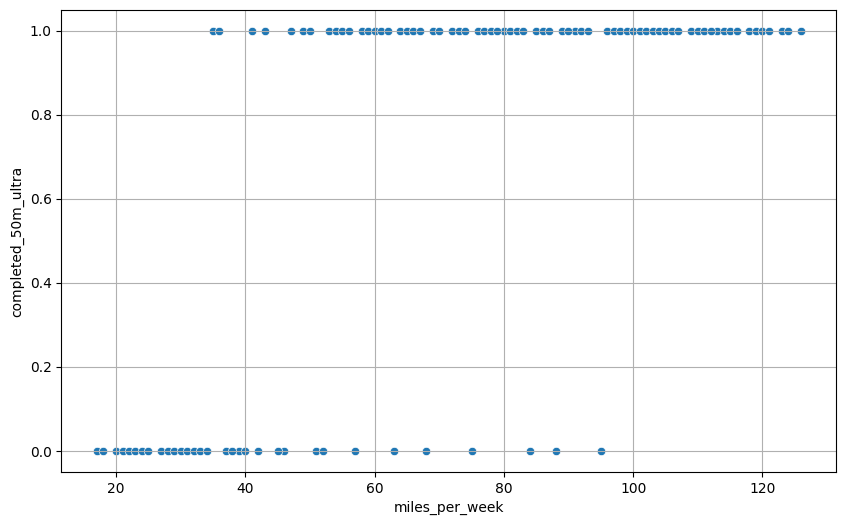

In [4]:
figure = plt.figure(figsize=(10,6))
sns.scatterplot(x='miles_per_week', y='completed_50m_ultra', data=df)
plt.grid()

<Axes: xlabel='completed_50m_ultra', ylabel='count'>

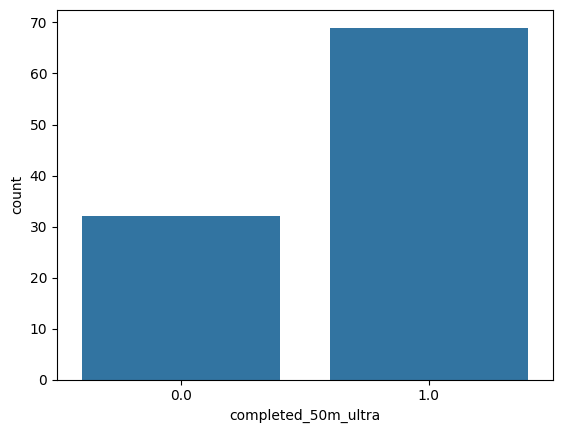

In [5]:
sns.countplot(x='completed_50m_ultra', data=df)

In [6]:
X = df[['miles_per_week']]
y = df.iloc[:, 1]
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=11)
print(X_train.shape)
print(X_test.shape)

(80, 1)
(21, 1)


In [12]:
m = LogisticRegression()
m.fit(X, y)
print(f"m: {m.coef_} | b: {m.intercept_}")

m: [[0.07376654]] | b: [-3.73938548]


In [8]:
y_pred = m.predict(X_test)
m.score(X_test, y_test)

0.9047619047619048

In [9]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[ 5  1]
 [ 1 14]]
              precision    recall  f1-score   support

         0.0       0.83      0.83      0.83         6
         1.0       0.93      0.93      0.93        15

    accuracy                           0.90        21
   macro avg       0.88      0.88      0.88        21
weighted avg       0.90      0.90      0.90        21



/Users/louisluri/Desktop/Python_Scripts/gpt-course/cuda/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


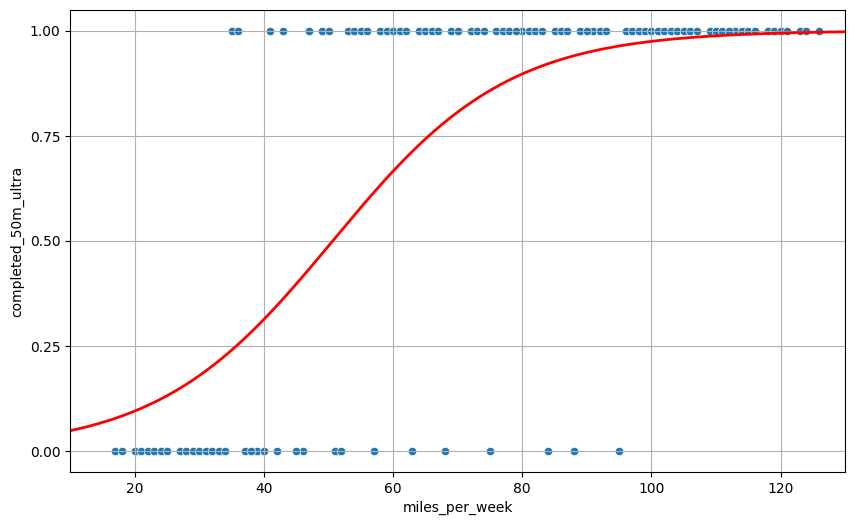

In [10]:
figure = plt.figure(figsize=(10,6))
sns.scatterplot(x='miles_per_week', y='completed_50m_ultra', data=df)
X_range = np.linspace(10, 130, 1000).reshape(-1, 1)
plt.plot(X_range, m.predict_proba(X_range)[:, 1], color='red', linewidth=2.0)
plt.xlim(10, 130)
plt.yticks([0, 0.25, 0.5, 0.75, 1.0])
plt.grid(0.1)